# STAC specification

The **SpatioTemporal Asset Catalog (STAC)** is an emerging open standard for geospatial data that aims to increase the interoperability of geospatial data, particularly satellite imagery. 
[Many major data archives](https://stacspec.org/en/about/datasets/) now follow the STAC specification.

In this lesson we'll be working with the [Microsoft's Planetary Computer (MPC)](https://planetarycomputer.microsoft.com) STAC API. 

## MPC Catalog 
First, load the necessary packages:

In [7]:
import rioxarray as rioxr
import geopandas as gpd
import matplotlib.pyplot as plt

from pystac_client import Client  # To access STAC catalogs
import planetary_computer  # To sign items from the MPC STAC catalog 

from IPython.display import Image  # To nicely display images

from shapely.geometry import shape # To turn GeoJSON dictionaries into geometries


### Access
We use the `Client` function from the `pystac_client` package to access the catalog:

In [8]:
# Access MPC catalog
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

The `modifier` parameter is needed to access the data in the MPC catalog.

### Catalog Exploration


In [9]:
# Explore catalog metadata
print('Title:', catalog.title)
print('Description:', catalog.description)

Title: Microsoft Planetary Computer STAC API
Description: Searchable spatiotemporal metadata describing Earth science datasets hosted by the Microsoft Planetary Computer


In [10]:
# Access catalog collections
catalog.get_collections()

<generator object Client.get_collections at 0x1747b6570>

Notice the output of get_collections() is a generator. This is a special kind of lazy object in Python that you can loop over like a list. Unlike a list, the items in a generator do not exist in memory until you explicitly iterate over them or convert them to a list. This can allow for more efficient memory allocation. Once the generator is exhausted (i.e. iterated over completely), it cannot be reused unless it is recreated.

Let’s try getting the collections from the catalog again:

In [11]:
# Get collections and print their names
collections = list(catalog.get_collections())  # Turn generator into list

print('Number of collections:', len(collections))

print("Collection IDs (first 10):")
for i in range(10):
    print('-', collections[i].id)

Number of collections: 139
Collection IDs (first 10):
- 3dep-lidar-classification
- 3dep-lidar-copc
- 3dep-lidar-dsm
- 3dep-lidar-dtm
- 3dep-lidar-dtm-native
- 3dep-lidar-hag
- 3dep-lidar-intensity
- 3dep-lidar-pointsourceid
- 3dep-lidar-returns
- 3dep-seamless


## Collection

The NAIP collection’s ID is 'naip'. We can select a single collection for exploration using the get_collection() method for the catalog and the collection ID as the parameter:

In [12]:
naip_collection = catalog.get_collection('naip')
naip_collection

<CollectionClient id=naip>

## Catalog search

We can narrow down the search within the catalog by specifying a time range, an area of interest, and the collection name. The simplest ways to define the area of interest to look for data in the catalog are:

- GeoJSON-type dictionary with the coordinates of the bounding box,
- a list [xmin, ymin, xmax, ymax] with the coordinate values defining the four corners of the bounding box.

In this lesson we will look for all the NAIP scenes over Santa Barbara available up to November 16, 2026. The .. at the start of the time range leaves the start date open, so the search returns every scene up to the end date. We’ll use the GeoJSON method to define the area of interest:

In [13]:
# Temporal range of interest
time_range = "../2026-11-16"

# NCEAS bounding box (as a GeoJSON, CRS=EPSG:4326)
aoi = {
    "type": "Polygon",
    "coordinates":[
        [
            [-119.70608227128903, 34.426300194372274],
            [-119.70608227128903, 34.42041139020533],
            [-119.6967885126002, 34.42041139020533],
            [-119.6967885126002, 34.426300194372274],
            [-119.70608227128903, 34.426300194372274] # Closes the bbox polygon
        ]
    ],
}

# Catalog search
search = catalog.search(
    collections = ['naip'],
    intersects = aoi,
    datetime = time_range)
search

To get the items found in the search (or check if there were any matches in the search) we use the item_collection() method:

In [14]:
# Retrieve search items
items = search.item_collection()
len(items)

7

This output tells us there were seven items in the catalog that matched our search!



In [15]:
items

## Item

### Check-In

Our search returned several items. Run the code below to see what distinguishes them.

```{python}
for scene in items:
    print(scene.id, scene.properties['datetime'], scene.properties['gsd'])
```

Here gsd stands for ground sample distance at the sensor, in meters (m). This is the pixel size of the raster.

What differs between the items besides the year?

- GSD -> 0.6 or 1.0 (pixel size)

Suppose you want to compare the vegetation around NCEAS with the 2018 image from the rioxarray lesson. Which item would you pick, and why?

- The 2018 file - same year


In [16]:
for scene in items:
    print(scene.id, scene.properties['datetime'], scene.properties['gsd'])

ca_m_3411935_sw_11_060_20240625 2024-06-25T16:00:00Z 0.6
ca_m_3411935_sw_11_060_20220513 2022-05-13T16:00:00Z 0.6
ca_m_3411935_sw_11_060_20200521 2020-05-21T00:00:00Z 0.6
ca_m_3411935_sw_11_060_20180724_20190209 2018-07-24T00:00:00Z 0.6
ca_m_3411935_sw_11_.6_20160713_20161004 2016-07-13T00:00:00Z 0.6
ca_m_3411935_sw_11_1_20140601_20141030 2014-06-01T00:00:00Z 1.0
ca_m_3411935_sw_11_1_20120505_20120730 2012-05-05T00:00:00Z 1.0


In our search the items are listed from newest to oldest, so items[0] is the most recent scene. We’ll work with this one for the rest of the lesson:

In [17]:
# Get first (most recent) item in the catalog search
item = items[0]
type(item)

pystac.item.Item

Remember the STAC item is the core object in a STAC catalog. The item does not contain the data itself, but rather metadata and assets. The assets contain links to access the actual data. Some of the metadata:

In [18]:
# Print item ID and properties
print('ID:' , item.id)
item.properties

ID: ca_m_3411935_sw_11_060_20240625


{'gsd': 0.6,
 'datetime': '2024-06-25T16:00:00Z',
 'naip:year': '2024',
 'proj:bbox': [246930.0, 3806808.0, 253260.0, 3814296.0],
 'proj:code': 'EPSG:26911',
 'providers': [{'url': 'https://www.fsa.usda.gov/programs-and-services/aerial-photography/imagery-programs/naip-imagery/',
   'name': 'USDA Farm Service Agency',
   'roles': ['producer', 'licensor']}],
 'naip:state': 'ca',
 'proj:shape': [12480, 10550],
 'proj:centroid': {'lat': 34.40624, 'lon': -119.71877},
 'proj:transform': [0.6, 0.0, 246930.0, 0.0, -0.6, 3814296.0, 0.0, 0.0, 1.0]}

In [22]:
item.geometry

{'type': 'Polygon',
 'coordinates': [[[-119.683292, 34.373269],
   [-119.685448, 34.440724],
   [-119.754272, 34.439192],
   [-119.752061, 34.371741],
   [-119.683292, 34.373269]]]}

In [ ]:
# Create geodataframes from aoi and the item
aoi_gdf = gpd.GeoDataFrame(geometry=[shape(aoi)], crs='EPSG:4326')
footprint = gpd.GeoDataFrame(geometry=[shape(item.geometry)], crs='EPSG:4326')

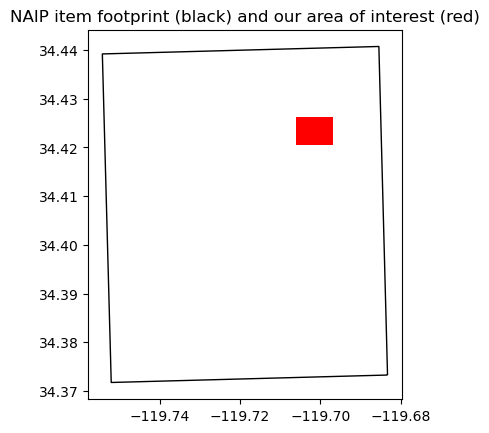

In [ ]:
# Plot both geodataframes
fig, ax = plt.subplots()
footprint.plot(ax=ax, color='none', edgecolor='black')
aoi_gdf.plot(ax=ax, color='red')
ax.set_title('NAIP item footprint (black) and our area of interest (red)')
plt.show()

### Check-In

From the item’s properties, when was this image taken, at what resolution, and in what CRS? Is the time of day in datetime believable?

- 2024-06-25T16:00:00Z
- 0.6m resolution (gsd)
- CRS: EPSG:26911

Just as the item properties, the item assets are given in a dictionary, with each value being a pystac.Asset. Let’s check the assets in the item:

In [19]:
item.assets

{'image': <Asset href=https://naipeuwest.blob.core.windows.net/naip/v002/ca/2024/ca_060cm_2024/34119/m_3411935_sw_11_060_20240625.tif?st=2026-11-18T18%3A17%3A20Z&se=2026-11-19T19%3A02%3A20Z&sp=rl&sv=2025-07-05&sr=c&skoid=9c8ff44a-6a2c-4dfb-b298-1c9212f64d9a&sktid=72f988bf-86f1-41af-91ab-2d7cd011db47&skt=2026-11-17T21%3A49%3A56Z&ske=2026-11-24T21%3A49%3A56Z&sks=b&skv=2025-07-05&sig=fg8GXT4K%2BIVKfJHpuH1Vz85Vqi/am1qCSXW2HmKAXRc%3D>,
 'thumbnail': <Asset href=https://naipeuwest.blob.core.windows.net/naip/v002/ca/2024/ca_060cm_2024/34119/m_3411935_sw_11_060_20240625.200.jpg?st=2026-11-18T18%3A17%3A20Z&se=2026-11-19T19%3A02%3A20Z&sp=rl&sv=2025-07-05&sr=c&skoid=9c8ff44a-6a2c-4dfb-b298-1c9212f64d9a&sktid=72f988bf-86f1-41af-91ab-2d7cd011db47&skt=2026-11-17T21%3A49%3A56Z&ske=2026-11-24T21%3A49%3A56Z&sks=b&skv=2025-07-05&sig=fg8GXT4K%2BIVKfJHpuH1Vz85Vqi/am1qCSXW2HmKAXRc%3D>}

In [20]:
for key in item.assets.keys():
    print(key, '--', item.assets[key].title)

image -- RGBIR COG tile
thumbnail -- Thumbnail


Notice each asset has an href, which is a link to the data. For example, we can use the URL for the 'thumbnail' asset to plot a small preview of the scene:

In [21]:
# Plot thumbnail preview
Image(url=item.assets['thumbnail'].href, width=300)

## Load data

The raster data in our current item is in the image asset. Again, we access this data via its URL. This time, we open it using rioxr.open_rasterio() directly:

In [26]:
sb = rioxr.open_rasterio(item.assets['image'].href)
sb

<xarray.DataArray (band: 4, y: 12480, x: 10550)> Size: 527MB
[526656000 values with dtype=uint8]
Coordinates:
  * band         (band) int64 32B 1 2 3 4
  * x            (x) float64 84kB 2.469e+05 2.469e+05 ... 2.533e+05 2.533e+05
  * y            (y) float64 100kB 3.814e+06 3.814e+06 ... 3.807e+06 3.807e+06
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    scale_factor:            1.0
    add_offset:              0.0

Notice the output doesn’t show any data values, only [526656000 values with dtype=uint8]. That’s because open_rasterio() only read the file’s metadata: its dimensions, coordinates and CRS. The data itself (about 500 MB) stays in the cloud until we use it, for example to plot it or to compute a statistic. This is the same lazy behavior we saw with generators. The NAIP files are stored as Cloud-Optimized GeoTIFFs (COGs), a format designed so we can read just the part of a file we need instead of downloading all of it.

Notice this raster has four bands (red, green, blue, nir), so we cannot plot it directly: .plot.imshow() would read the fourth band (NIR) as transparency. Thus we need to select the bands we want to plot (RGB) before plotting:

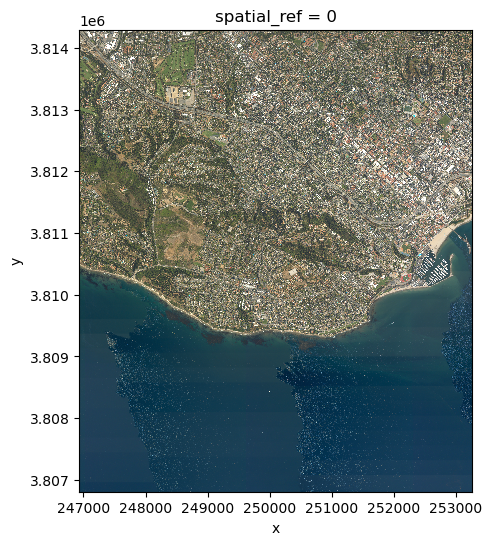

In [27]:
# Plot raster with correct ratio
size = 6  
aspect = sb.rio.width / sb.rio.height 
# Select R,G,B bands and plot
sb.sel(band=[1,2,3]).plot.imshow(size=size, aspect=aspect)